<a href="https://colab.research.google.com/github/Ayushpaithankar/PathSnap/blob/main/PathSnap_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PathSnap on Colab

This notebook has two separate sections. **Saved experiment graphs** reproduce the published review results and run immediately; they are not evidence of training in this Colab session. **Fresh training evidence** reads the original trip data, generates features, tunes LightGBM, evaluates all methods, and shows newly produced metrics and model artifacts. Run the entire training section and retain its outputs when showing a live training record.

Upload `PathSnap_Evaluator_Ready.zip` (or the earlier `PathSnap_Reviewed.zip`) in Colab's Files pane for fresh training. The archive includes `inputs/Student folder.zip`, which contains the 80 training and 10 student-test trips as `.track`, `.nodes`, `.arcs`, and `.route` files. The pipeline reads these directly; no additional CSV upload is needed. A full decoder evaluation can take hours on a hosted CPU.

In [ ]:
from io import StringIO
import pandas as pd
from IPython.display import display

saved_summary = 'method,point_top1,decoded_top1,route_f1,trusted_covered_log_loss\nNearest road,0.5294885177453027,0.8850730688935282,0.9313473256601219,0.9404138759548042\nDistance + heading,0.7926409185803758,0.8701983298538623,0.936657131181038,0.7177565664388874\nLightGBM untuned,0.91419624217119,0.8853340292275574,0.9215528781793842,0.25662930959879865\nLightGBM tuned without context,0.88580375782881,0.8805845511482254,0.9281469475958941,0.3029060273964671\nLightGBM tuned,0.9173799582463465,0.878705636743215,0.9364539393114709,0.24151827891859795\nHistGradientBoosting,0.904384133611691,0.8805845511482254,0.9193742478941035,0.26797103948480583'
summary = pd.read_csv(StringIO(saved_summary)).set_index('method')
show = summary.rename(columns={
    'point_top1': 'Before Viterbi',
    'decoded_top1': 'After Viterbi',
    'route_f1': 'Ordered route F1',
    'trusted_covered_log_loss': 'Covered log loss',
})
print('Verified review release • 10 student-test trips • 19,160 observations')
display(show.style.format({'Before Viterbi': '{:.2%}', 'After Viterbi': '{:.2%}',
                           'Ordered route F1': '{:.2%}', 'Covered log loss': '{:.3f}'}))

Verified review release • 10 student-test trips • 19,160 observations


,Before Viterbi,After Viterbi,Ordered route F1,Covered log loss
method,,,,
Nearest road,52.95%,88.51%,93.13%,0.940
Distance + heading,79.26%,87.02%,93.67%,0.718
LightGBM untuned,91.42%,88.53%,92.16%,0.257
LightGBM tuned without context,88.58%,88.06%,92.81%,0.303
LightGBM tuned,91.74%,87.87%,93.65%,0.242
HistGradientBoosting,90.44%,88.06%,91.94%,0.268


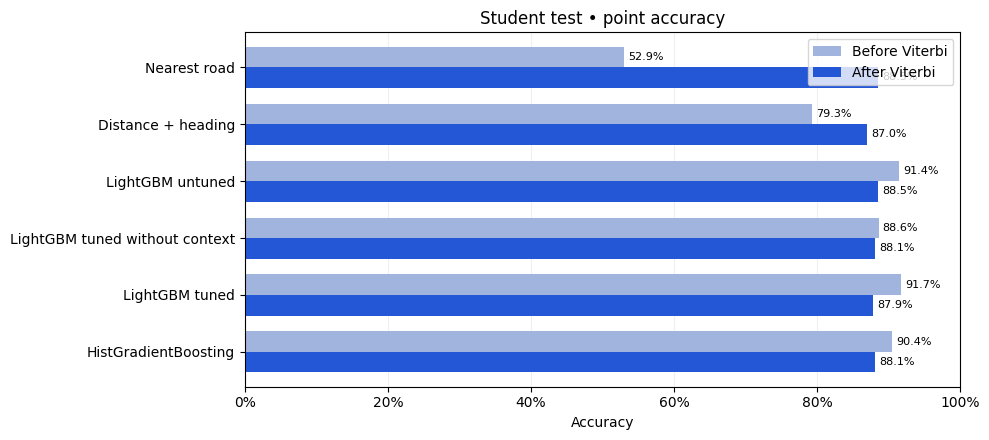

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ax = show[['Before Viterbi', 'After Viterbi']].plot.barh(
    figsize=(10, 4.5), color=['#a1b4de', '#2457d6'], width=.72
)
ax.set(title='Student test • point accuracy', xlabel='Accuracy', ylabel='', xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.invert_yaxis()
ax.grid(axis='x', alpha=.2)
ax.set_axisbelow(True)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{value:.1%}' for value in container.datavalues],
                 padding=3, fontsize=8)
plt.tight_layout()
plt.show()

## Additional experiment graphs

These plots use the saved review experiment, not a fresh Colab run. Trip IDs retain their leading zeroes. Run the cells below to display model metrics, per-trip results, grouped cross-validation, and tuning history.

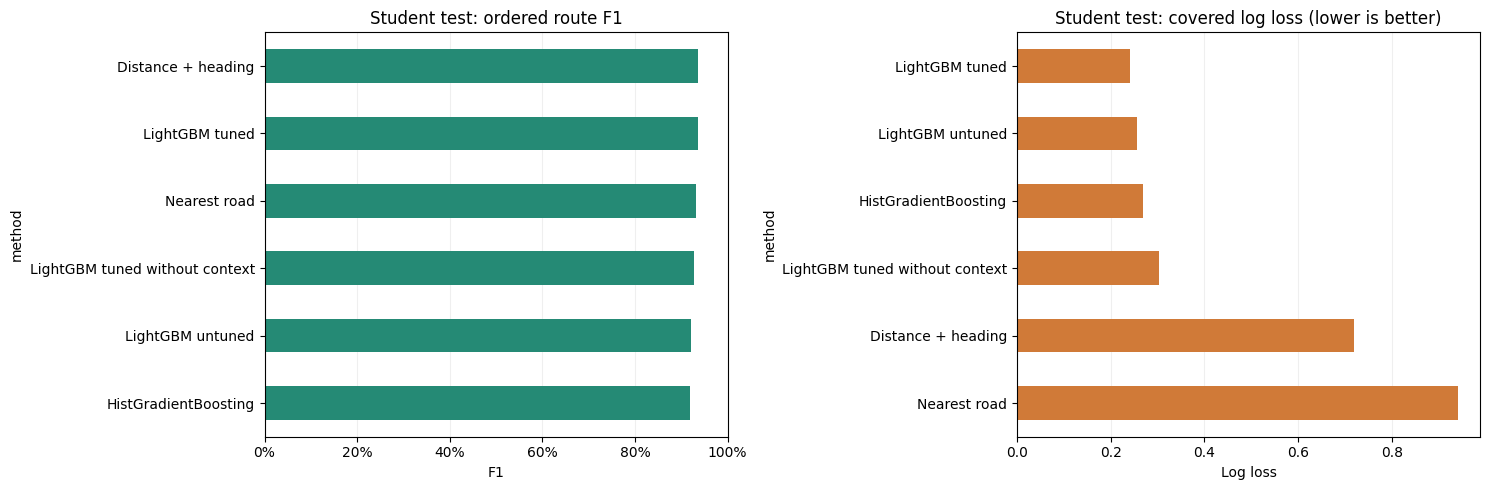

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
show['Ordered route F1'].sort_values().plot.barh(ax=axes[0], color='#258a75')
axes[0].set(title='Student test: ordered route F1', xlabel='F1', xlim=(0, 1))
axes[0].xaxis.set_major_formatter(PercentFormatter(xmax=1))
show['Covered log loss'].sort_values(ascending=False).plot.barh(ax=axes[1], color='#d07a38')
axes[1].set(title='Student test: covered log loss (lower is better)', xlabel='Log loss')
for ax in axes:
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

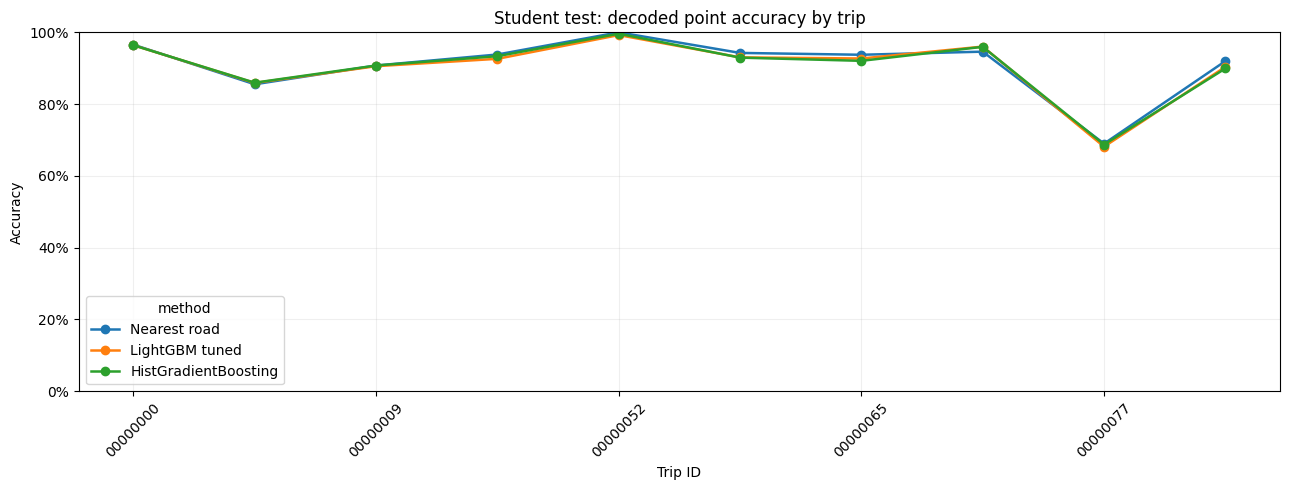

In [ ]:
per_trip = pd.read_csv(StringIO('method,trip_id,decoded_correct,observations\nNearest road,00000000,2417,2503\nDistance + heading,00000000,2415,2503\nLightGBM untuned,00000000,2413,2503\nLightGBM tuned without context,00000000,2393,2503\nLightGBM tuned,00000000,2413,2503\nHistGradientBoosting,00000000,2413,2503\nNearest road,00000007,1158,1354\nDistance + heading,00000007,1164,1354\nLightGBM untuned,00000007,1163,1354\nLightGBM tuned without context,00000007,1164,1354\nLightGBM tuned,00000007,1163,1354\nHistGradientBoosting,00000007,1164,1354\nNearest road,00000009,952,1049\nDistance + heading,00000009,919,1049\nLightGBM untuned,00000009,953,1049\nLightGBM tuned without context,00000009,949,1049\nLightGBM tuned,00000009,950,1049\nHistGradientBoosting,00000009,952,1049\nNearest road,00000040,2810,2995\nDistance + heading,00000040,2797,2995\nLightGBM untuned,00000040,2799,2995\nLightGBM tuned without context,00000040,2813,2995\nLightGBM tuned,00000040,2774,2995\nHistGradientBoosting,00000040,2796,2995\nNearest road,00000052,262,262\nDistance + heading,00000052,252,262\nLightGBM untuned,00000052,260,262\nLightGBM tuned without context,00000052,260,262\nLightGBM tuned,00000052,260,262\nHistGradientBoosting,00000052,261,262\nNearest road,00000056,3731,3958\nDistance + heading,00000056,3673,3958\nLightGBM untuned,00000056,3686,3958\nLightGBM tuned without context,00000056,3673,3958\nLightGBM tuned,00000056,3682,3958\nHistGradientBoosting,00000056,3679,3958\nNearest road,00000065,720,768\nDistance + heading,00000065,691,768\nLightGBM untuned,00000065,707,768\nLightGBM tuned without context,00000065,699,768\nLightGBM tuned,00000065,712,768\nHistGradientBoosting,00000065,707,768\nNearest road,00000076,1406,1486\nDistance + heading,00000076,1400,1486\nLightGBM untuned,00000076,1430,1486\nLightGBM tuned without context,00000076,1418,1486\nLightGBM tuned,00000076,1427,1486\nHistGradientBoosting,00000076,1426,1486\nNearest road,00000077,2698,3911\nDistance + heading,00000077,2593,3911\nLightGBM untuned,00000077,2750,3911\nLightGBM tuned without context,00000077,2728,3911\nLightGBM tuned,00000077,2665,3911\nHistGradientBoosting,00000077,2688,3911\nNearest road,00000091,804,874\nDistance + heading,00000091,769,874\nLightGBM untuned,00000091,802,874\nLightGBM tuned without context,00000091,775,874\nLightGBM tuned,00000091,790,874\nHistGradientBoosting,00000091,786,874\n'), dtype={'trip_id': str})
per_trip['decoded_accuracy'] = per_trip['decoded_correct'] / per_trip['observations']
chosen = ['Nearest road', 'LightGBM tuned', 'HistGradientBoosting']
pivot = per_trip[per_trip.method.isin(chosen)].pivot(index='trip_id', columns='method', values='decoded_accuracy')
ax = pivot[chosen].plot(figsize=(13, 5), marker='o', linewidth=1.8)
ax.set(title='Student test: decoded point accuracy by trip', xlabel='Trip ID', ylabel='Accuracy', ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=.2)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

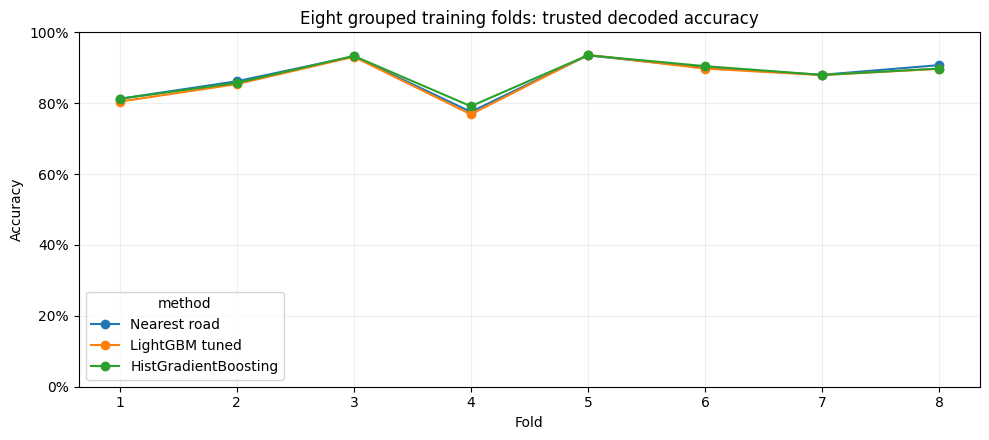

In [ ]:
cv_folds = pd.read_csv(StringIO('method,fold,trusted_decoded_correct,trusted_observations\nDistance + heading,1,12721,15783\nDistance + heading,2,12993,15316\nDistance + heading,3,13966,15211\nDistance + heading,4,10809,14543\nDistance + heading,5,13755,14876\nDistance + heading,6,13247,14886\nDistance + heading,7,13100,15071\nDistance + heading,8,13211,14747\nHistGradientBoosting,1,12823,15783\nHistGradientBoosting,2,13131,15316\nHistGradientBoosting,3,14198,15211\nHistGradientBoosting,4,11510,14543\nHistGradientBoosting,5,13914,14876\nHistGradientBoosting,6,13466,14886\nHistGradientBoosting,7,13260,15071\nHistGradientBoosting,8,13238,14747\nLightGBM tuned,1,12697,15783\nLightGBM tuned,2,13078,15316\nLightGBM tuned,3,14162,15211\nLightGBM tuned,4,11178,14543\nLightGBM tuned,5,13931,14876\nLightGBM tuned,6,13364,14886\nLightGBM tuned,7,13252,15071\nLightGBM tuned,8,13229,14747\nLightGBM tuned without context,1,12761,15783\nLightGBM tuned without context,2,13084,15316\nLightGBM tuned without context,3,14076,15211\nLightGBM tuned without context,4,11228,14543\nLightGBM tuned without context,5,13860,14876\nLightGBM tuned without context,6,13418,14886\nLightGBM tuned without context,7,13098,15071\nLightGBM tuned without context,8,13208,14747\nLightGBM untuned,1,12871,15783\nLightGBM untuned,2,13120,15316\nLightGBM untuned,3,14184,15211\nLightGBM untuned,4,11729,14543\nLightGBM untuned,5,13955,14876\nLightGBM untuned,6,13472,14886\nLightGBM untuned,7,13291,15071\nLightGBM untuned,8,13292,14747\nNearest road,1,12823,15783\nNearest road,2,13202,15316\nNearest road,3,14177,15211\nNearest road,4,11280,14543\nNearest road,5,13909,14876\nNearest road,6,13398,14886\nNearest road,7,13265,15071\nNearest road,8,13382,14747\n'))
cv_folds['decoded_accuracy'] = cv_folds.trusted_decoded_correct / cv_folds.trusted_observations
fold_table = cv_folds[cv_folds.method.isin(chosen)].pivot(index='fold', columns='method', values='decoded_accuracy')
ax = fold_table[chosen].plot(figsize=(10, 4.5), marker='o')
ax.set(title='Eight grouped training folds: trusted decoded accuracy', xlabel='Fold', ylabel='Accuracy', ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

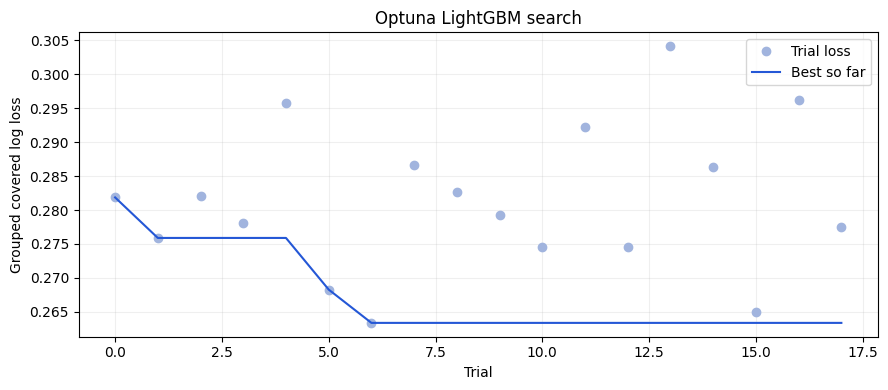

In [ ]:
trials = pd.read_csv(StringIO('number,value\n0,0.2818575271251841\n1,0.2758886766559826\n2,0.282118366665983\n3,0.2781605501104793\n4,0.2958337627501123\n5,0.2682811411214587\n6,0.2633765515678682\n7,0.286661398748101\n8,0.2826725898020823\n9,0.2792837047286191\n10,0.2745649842077568\n11,0.2922963028020534\n12,0.2746139575917111\n13,0.3041346521690775\n14,0.2863577808902155\n15,0.2650208436061302\n16,0.2962354274732394\n17,0.2774581915550712\n'))
trials['best_so_far'] = trials['value'].cummin()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(trials['number'], trials['value'], 'o', color='#a1b4de', label='Trial loss')
ax.plot(trials['number'], trials['best_so_far'], color='#2457d6', label='Best so far')
ax.set(title='Optuna LightGBM search', xlabel='Trial', ylabel='Grouped covered log loss')
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

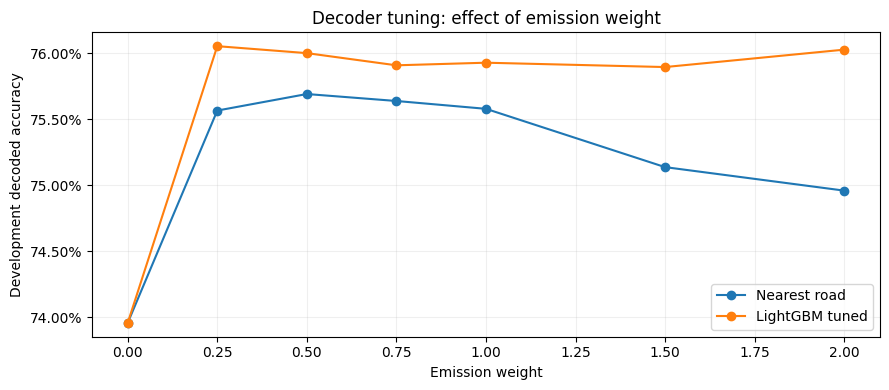

In [ ]:
sweeps = pd.read_csv(StringIO('method,sweep,coordinate,emission_weight,top1\nNearest road,1,emission_weight,0.0,0.7395805855974676\nNearest road,1,emission_weight,0.25,0.7556713268266948\nNearest road,1,emission_weight,0.5,0.7569242943814297\nNearest road,1,emission_weight,0.75,0.7563967290952255\nNearest road,1,emission_weight,1.0,0.7558032181482458\nNearest road,1,emission_weight,1.5,0.7513848588762859\nNearest road,1,emission_weight,2.0,0.7496043260353469\nNearest road,2,beta_multiplier,0.5,0.742416249010815\nNearest road,2,beta_multiplier,0.5,0.7498021630176734\nNearest road,2,beta_multiplier,0.5,0.7552756528620417\nNearest road,2,beta_multiplier,0.5,0.7569242943814297\nNearest road,2,beta_multiplier,0.5,0.75633078343445\nNearest road,2,beta_multiplier,0.5,0.7555394355051438\nNearest road,3,max_gap_s,0.5,0.7571221313637563\nNearest road,3,max_gap_s,0.5,0.7569902400422053\nNearest road,3,max_gap_s,0.5,0.7569242943814297\nNearest road,3,max_gap_s,0.5,0.7569242943814297\nNearest road,3,max_gap_s,0.5,0.7569242943814297\nNearest road,4,max_speed_mps,0.5,0.7581772619361646\nNearest road,4,max_speed_mps,0.5,0.7571221313637563\nNearest road,4,max_speed_mps,0.5,0.7571221313637563\nNearest road,4,max_speed_mps,0.5,0.7572540226853073\nNearest road,4,max_speed_mps,0.5,0.7572540226853073\nNearest road,5,emission_weight,0.0,0.7401740965444473\nNearest road,5,emission_weight,0.25,0.7567924030598786\nNearest road,5,emission_weight,0.5,0.7581772619361646\nNearest road,5,emission_weight,0.75,0.7577815879715115\nNearest road,5,emission_weight,1.0,0.757847533632287\nNearest road,5,emission_weight,1.5,0.7535610656818781\nNearest road,5,emission_weight,2.0,0.7525059351094698\nNearest road,6,beta_multiplier,0.5,0.7441308361909786\nNearest road,6,beta_multiplier,0.5,0.7513848588762859\nNearest road,6,beta_multiplier,0.5,0.7569902400422053\nNearest road,6,beta_multiplier,0.5,0.7581772619361646\nNearest road,6,beta_multiplier,0.5,0.757715642310736\nNearest road,6,beta_multiplier,0.5,0.7569902400422053\nDistance + heading,1,emission_weight,0.0,0.7395805855974676\nDistance + heading,1,emission_weight,0.25,0.7494064890530203\nDistance + heading,1,emission_weight,0.5,0.7490108150883672\nDistance + heading,1,emission_weight,0.75,0.7491427064099182\nDistance + heading,1,emission_weight,1.0,0.748219467159061\nDistance + heading,1,emission_weight,1.5,0.7457135320495911\nDistance + heading,1,emission_weight,2.0,0.7441308361909786\nDistance + heading,2,beta_multiplier,0.25,0.7378659984173042\nDistance + heading,2,beta_multiplier,0.25,0.7420865207069375\nDistance + heading,2,beta_multiplier,0.25,0.7479556845159588\nDistance + heading,2,beta_multiplier,0.25,0.7494064890530203\nDistance + heading,2,beta_multiplier,0.25,0.7500659456607756\nDistance + heading,2,beta_multiplier,0.25,0.7505935109469797\nDistance + heading,3,max_gap_s,0.25,0.7507254022685307\nDistance + heading,3,max_gap_s,0.25,0.7505935109469797\nDistance + heading,3,max_gap_s,0.25,0.7505935109469797\nDistance + heading,3,max_gap_s,0.25,0.7505935109469797\nDistance + heading,3,max_gap_s,0.25,0.7505935109469797\nDistance + heading,4,max_speed_mps,0.25,0.751648641519388\nDistance + heading,4,max_speed_mps,0.25,0.7507254022685307\nDistance + heading,4,max_speed_mps,0.25,0.7507254022685307\nDistance + heading,4,max_speed_mps,0.25,0.7508572935900818\nDistance + heading,4,max_speed_mps,0.25,0.7508572935900818\nDistance + heading,5,emission_weight,0.0,0.7418227380638354\nDistance + heading,5,emission_weight,0.25,0.751648641519388\nDistance + heading,5,emission_weight,0.5,0.7504616196254287\nDistance + heading,5,emission_weight,0.75,0.7469005539435505\nDistance + heading,5,emission_weight,1.0,0.7465708256396729\nDistance + heading,5,emission_weight,1.5,0.7457135320495911\nDistance + heading,5,emission_weight,2.0,0.7432735426008968\nDistance + heading,6,beta_multiplier,0.25,0.7394486942759166\nDistance + heading,6,beta_multiplier,0.25,0.743537325243999\nDistance + heading,6,beta_multiplier,0.25,0.748351358480612\nDistance + heading,6,beta_multiplier,0.25,0.7504616196254287\nDistance + heading,6,beta_multiplier,0.25,0.7511210762331838\nDistance + heading,6,beta_multiplier,0.25,0.751648641519388\nLightGBM untuned,1,emission_weight,0.0,0.7395805855974676\nLightGBM untuned,1,emission_weight,0.25,0.7595621208124506\nLightGBM untuned,1,emission_weight,0.5,0.7591664468477974\nLightGBM untuned,1,emission_weight,0.75,0.7592983381693484\nLightGBM untuned,1,emission_weight,1.0,0.7597599577947771\nLightGBM untuned,1,emission_weight,1.5,0.7616064362964917\nLightGBM untuned,1,emission_weight,2.0,0.7616723819572672\nLightGBM untuned,2,beta_multiplier,2.0,0.7599577947771037\nLightGBM untuned,2,beta_multiplier,2.0,0.761012925349512\nLightGBM untuned,2,beta_multiplier,2.0,0.7609469796887365\nLightGBM untuned,2,beta_multiplier,2.0,0.7616723819572672\nLightGBM untuned,2,beta_multiplier,2.0,0.7614745449749406\nLightGBM untuned,2,beta_multiplier,2.0,0.7606831970456344\nLightGBM untuned,3,max_gap_s,2.0,0.7618042732788183\nLightGBM untuned,3,max_gap_s,2.0,0.7616723819572672\nLightGBM untuned,3,max_gap_s,2.0,0.7616723819572672\nLightGBM untuned,3,max_gap_s,2.0,0.7616723819572672\nLightGBM untuned,3,max_gap_s,2.0,0.7616723819572672\nLightGBM untuned,4,max_speed_mps,2.0,0.762265892904247\nLightGBM untuned,4,max_speed_mps,2.0,0.7618042732788183\nLightGBM untuned,4,max_speed_mps,2.0,0.7618042732788183\nLightGBM untuned,4,max_speed_mps,2.0,0.7618702189395937\nLightGBM untuned,4,max_speed_mps,2.0,0.7618702189395937\nLightGBM untuned,5,emission_weight,0.0,0.7401740965444473\nLightGBM untuned,5,emission_weight,0.25,0.7600237404378792\nLightGBM untuned,5,emission_weight,0.5,0.7616723819572672\nLightGBM untuned,5,emission_weight,0.75,0.7618042732788183\nLightGBM untuned,5,emission_weight,1.0,0.762265892904247\nLightGBM untuned,5,emission_weight,1.5,0.762265892904247\nLightGBM untuned,5,emission_weight,2.0,0.762265892904247\nLightGBM untuned,6,beta_multiplier,2.0,0.7617383276180427\nLightGBM untuned,6,beta_multiplier,2.0,0.7635188604589818\nLightGBM untuned,6,beta_multiplier,2.0,0.7623318385650224\nLightGBM untuned,6,beta_multiplier,2.0,0.762265892904247\nLightGBM untuned,6,beta_multiplier,2.0,0.7618702189395937\nLightGBM untuned,6,beta_multiplier,2.0,0.7608810340279609\nLightGBM tuned without context,1,emission_weight,0.0,0.7395805855974676\nLightGBM tuned without context,1,emission_weight,0.25,0.7575178053284094\nLightGBM tuned without context,1,emission_weight,0.5,0.7568583487206542\nLightGBM tuned without context,1,emission_weight,0.75,0.7554734898443682\nLightGBM tuned without context,1,emission_weight,1.0,0.7569902400422053\nLightGBM tuned without context,1,emission_weight,1.5,0.7572540226853073\nLightGBM tuned without context,1,emission_weight,2.0,0.7561329464521235\nLightGBM tuned without context,2,beta_multiplier,0.25,0.7509232392508572\nLightGBM tuned without context,2,beta_multiplier,0.25,0.754682141915062\nLightGBM tuned without context,2,beta_multiplier,0.25,0.7576496966499604\nLightGBM tuned without context,2,beta_multiplier,0.25,0.7575178053284094\nLightGBM tuned without context,2,beta_multiplier,0.25,0.7567924030598786\nLightGBM tuned without context,2,beta_multiplier,0.25,0.757583750989185\nLightGBM tuned without context,3,max_gap_s,0.25,0.757583750989185\nLightGBM tuned without context,3,max_gap_s,0.25,0.7576496966499604\nLightGBM tuned without context,3,max_gap_s,0.25,0.7576496966499604\nLightGBM tuned without context,3,max_gap_s,0.25,0.7576496966499604\nLightGBM tuned without context,3,max_gap_s,0.25,0.7576496966499604\nLightGBM tuned without context,4,max_speed_mps,0.25,0.7586388815615932\nLightGBM tuned without context,4,max_speed_mps,0.25,0.7576496966499604\nLightGBM tuned without context,4,max_speed_mps,0.25,0.7576496966499604\nLightGBM tuned without context,4,max_speed_mps,0.25,0.7576496966499604\nLightGBM tuned without context,4,max_speed_mps,0.25,0.7576496966499604\nLightGBM tuned without context,5,emission_weight,0.0,0.7401740965444473\nLightGBM tuned without context,5,emission_weight,0.25,0.7586388815615932\nLightGBM tuned without context,5,emission_weight,0.5,0.7594302294908994\nLightGBM tuned without context,5,emission_weight,0.75,0.7588367185439198\nLightGBM tuned without context,5,emission_weight,1.0,0.7582432075969401\nLightGBM tuned without context,5,emission_weight,1.5,0.7573199683460828\nLightGBM tuned without context,5,emission_weight,2.0,0.7591005011870219\nLightGBM tuned without context,6,beta_multiplier,0.5,0.7542205222896333\nLightGBM tuned without context,6,beta_multiplier,0.5,0.7570561857029807\nLightGBM tuned without context,6,beta_multiplier,0.5,0.7594302294908994\nLightGBM tuned without context,6,beta_multiplier,0.5,0.7585729359008178\nLightGBM tuned without context,6,beta_multiplier,0.5,0.7581113162753891\nLightGBM tuned without context,6,beta_multiplier,0.5,0.7588367185439198\nLightGBM tuned,1,emission_weight,0.0,0.7395805855974676\nLightGBM tuned,1,emission_weight,0.25,0.7605513057240834\nLightGBM tuned,1,emission_weight,0.5,0.7600237404378792\nLightGBM tuned,1,emission_weight,0.75,0.7591005011870219\nLightGBM tuned,1,emission_weight,1.0,0.7592983381693484\nLightGBM tuned,1,emission_weight,1.5,0.7589686098654709\nLightGBM tuned,1,emission_weight,2.0,0.7602875230809812\nLightGBM tuned,2,beta_multiplier,0.25,0.7533632286995515\nLightGBM tuned,2,beta_multiplier,0.25,0.7567924030598786\nLightGBM tuned,2,beta_multiplier,0.25,0.7598259034555527\nLightGBM tuned,2,beta_multiplier,0.25,0.7605513057240834\nLightGBM tuned,2,beta_multiplier,0.25,0.759364283830124\nLightGBM tuned,2,beta_multiplier,0.25,0.7579134792930625\nLightGBM tuned,3,max_gap_s,0.25,0.7613426536533896\nLightGBM tuned,3,max_gap_s,0.25,0.7605513057240834\nLightGBM tuned,3,max_gap_s,0.25,0.7605513057240834\nLightGBM tuned,3,max_gap_s,0.25,0.7605513057240834\nLightGBM tuned,3,max_gap_s,0.25,0.7605513057240834\nLightGBM tuned,4,max_speed_mps,0.25,0.7623318385650224\nLightGBM tuned,4,max_speed_mps,0.25,0.7613426536533896\nLightGBM tuned,4,max_speed_mps,0.25,0.7613426536533896\nLightGBM tuned,4,max_speed_mps,0.25,0.7614745449749406\nLightGBM tuned,4,max_speed_mps,0.25,0.7614745449749406\nLightGBM tuned,5,emission_weight,0.0,0.7401740965444473\nLightGBM tuned,5,emission_weight,0.25,0.7623318385650224\nLightGBM tuned,5,emission_weight,0.5,0.7621340015826958\nLightGBM tuned,5,emission_weight,0.75,0.7614085993141652\nLightGBM tuned,5,emission_weight,1.0,0.7613426536533896\nLightGBM tuned,5,emission_weight,1.5,0.7603534687417568\nLightGBM tuned,5,emission_weight,2.0,0.7606172513848589\nLightGBM tuned,6,beta_multiplier,0.25,0.7549459245581641\nLightGBM tuned,6,beta_multiplier,0.25,0.7583750989184912\nLightGBM tuned,6,beta_multiplier,0.25,0.7618702189395937\nLightGBM tuned,6,beta_multiplier,0.25,0.7623318385650224\nLightGBM tuned,6,beta_multiplier,0.25,0.7616723819572672\nLightGBM tuned,6,beta_multiplier,0.25,0.7596940121340016\nHistGradientBoosting,1,emission_weight,0.0,0.7395805855974676\nHistGradientBoosting,1,emission_weight,0.25,0.7620680559219203\nHistGradientBoosting,1,emission_weight,0.5,0.7613426536533896\nHistGradientBoosting,1,emission_weight,0.75,0.7606831970456344\nHistGradientBoosting,1,emission_weight,1.0,0.7620680559219203\nHistGradientBoosting,1,emission_weight,1.5,0.7618042732788183\nHistGradientBoosting,1,emission_weight,2.0,0.7616064362964917\nHistGradientBoosting,2,beta_multiplier,1.0,0.7587707728831443\nHistGradientBoosting,2,beta_multiplier,1.0,0.7630572408335532\nHistGradientBoosting,2,beta_multiplier,1.0,0.762265892904247\nHistGradientBoosting,2,beta_multiplier,1.0,0.7620680559219203\nHistGradientBoosting,2,beta_multiplier,1.0,0.7606831970456344\nHistGradientBoosting,2,beta_multiplier,1.0,0.7613426536533896\nHistGradientBoosting,3,max_gap_s,1.0,0.764310208388288\nHistGradientBoosting,3,max_gap_s,1.0,0.7630572408335532\nHistGradientBoosting,3,max_gap_s,1.0,0.7630572408335532\nHistGradientBoosting,3,max_gap_s,1.0,0.7630572408335532\nHistGradientBoosting,3,max_gap_s,1.0,0.7630572408335532\nHistGradientBoosting,4,max_speed_mps,1.0,0.7652993932999209\nHistGradientBoosting,4,max_speed_mps,1.0,0.764310208388288\nHistGradientBoosting,4,max_speed_mps,1.0,0.764310208388288\nHistGradientBoosting,4,max_speed_mps,1.0,0.7644420997098391\nHistGradientBoosting,4,max_speed_mps,1.0,0.7644420997098391\nHistGradientBoosting,5,emission_weight,0.0,0.7383276180427328\nHistGradientBoosting,5,emission_weight,0.25,0.7554734898443682\nHistGradientBoosting,5,emission_weight,0.5,0.7609469796887365\nHistGradientBoosting,5,emission_weight,0.75,0.7631891321551042\nHistGradientBoosting,5,emission_weight,1.0,0.7652993932999209\nHistGradientBoosting,5,emission_weight,1.5,0.764178317066737\nHistGradientBoosting,5,emission_weight,2.0,0.7644420997098391\nHistGradientBoosting,6,beta_multiplier,1.0,0.7604853600633078\nHistGradientBoosting,6,beta_multiplier,1.0,0.7652993932999209\nHistGradientBoosting,6,beta_multiplier,1.0,0.7647058823529411\nHistGradientBoosting,6,beta_multiplier,1.0,0.7633869691374308\nHistGradientBoosting,6,beta_multiplier,1.0,0.7613426536533896\nHistGradientBoosting,6,beta_multiplier,1.0,0.7620021102611448\n'))
fig, ax = plt.subplots(figsize=(9, 4))
for method in ['Nearest road', 'LightGBM tuned']:
    part = sweeps[(sweeps.method == method) & (sweeps.sweep == 1) & (sweeps.coordinate == 'emission_weight')]
    ax.plot(part.emission_weight, part.top1, marker='o', label=method)
ax.set(title='Decoder tuning: effect of emission weight', xlabel='Emission weight', ylabel='Development decoded accuracy')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## How to read the comparison

- **Point accuracy** compares one predicted directed arc per GPS reading against its ordered-alignment label.
- **Route F1** compares the ordered predictions against the original reference route. It measures a different property than point accuracy.
- **Covered log loss** measures probability assigned to the correct arc on trusted points with a reference candidate. Candidate misses still count against point accuracy.

The tuned ranker leads before decoding. Nearest road plus Viterbi is the release default because the tuned ranker did not improve decoded accuracy on held-out training trips.

## Reproduce training and evaluation

The project ZIP contains the original development data. For a Colab local runtime, set `PROJECT_DIR` to your extracted project folder. For a hosted runtime, upload the ZIP first. Each stage streams its output and stops on failure. The active runtime must support the versions in `requirements-training.txt`.

## Five trained model families: saved experiment record

This earlier ordered-label experiment trained **Conditional logit, a grouped MLP, ExtraTrees, LightGBM LambdaRank, and HistGradientBoosting** using two repetitions of eight trip-grouped folds. The two road rules are baselines. The tables below come from the project's saved CSV files. They document prior measured runs; the fresh reproduction cells later in this notebook execute the training code in your Colab runtime.

,CV top-1,CV grouped log loss,Student top-1,Student decoded top-1
model,,,,
Conditional logit,76.71%,3.479,85.43%,87.29%
Grouped MLP,77.28%,3.398,86.21%,87.44%
ExtraTrees,77.05%,3.415,86.29%,87.75%
LightGBM ranker,78.00%,3.374,88.31%,88.25%
HistGradientBoosting,77.77%,3.397,87.48%,88.60%


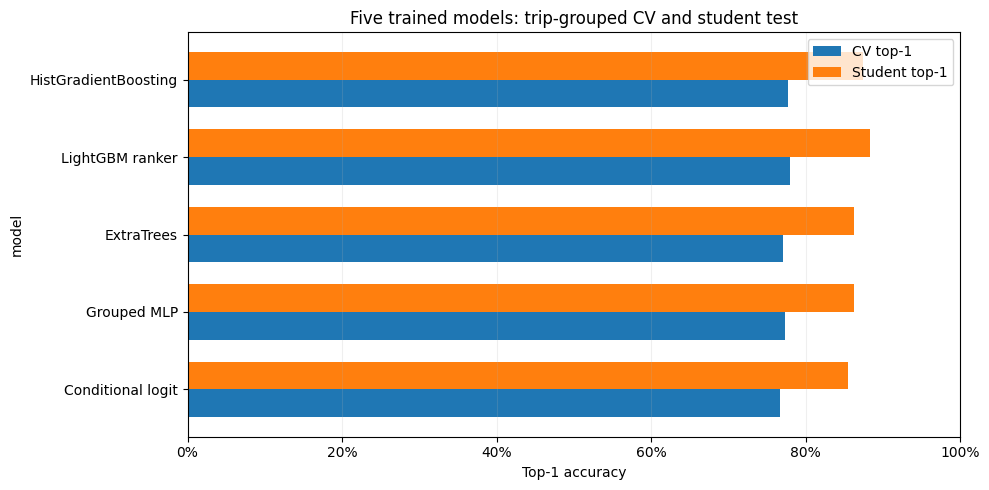

In [ ]:
five_cv = pd.read_csv(StringIO('model,top1,grouped_log_loss,paired_top1_delta_vs_rule,paired_top1_delta_sd\nNearest road,0.4922852916549411,3.898207124171022,-0.1961459419603505,0.0724561060009646\nDistance + heading,0.6884312336152917,3.6958208389244422,0.0,0.0\nConditional logit,0.7670671159954894,3.4785723010943954,0.0786358823801978,0.0434782395498265\nGrouped MLP,0.7727574641233567,3.3984046852417946,0.084326230508065,0.0409626251366949\nExtraTrees,0.770489980666265,3.415046567031246,0.0820587470509732,0.0449306301343716\nLightGBM ranker,0.77995074120268,3.3736581509235553,0.0915195075873883,0.0427769393637569\nHistGradientBoosting,0.7777193223266698,3.397428443946563,0.0892880887113781,0.0464359063100132\n')).set_index('model')
five_test = pd.read_csv(StringIO('model,selected,observations,classifier_top1,grouped_log_loss,decoded_top1,sequence_f1\nNearest road,False,19160,0.5294885177453027,1.0461258542344811,0.8838204592901879,0.918744971842317\nDistance + heading,False,19160,0.7926409185803758,0.77711167014622,0.8742171189979123,0.9148113584855352\nConditional logit,False,19160,0.8543319415448852,0.5698264356770822,0.8728601252609604,0.9100543118293812\nGrouped MLP,False,19160,0.8621085594989562,0.4683842795689071,0.8743736951983299,0.916644402885386\nExtraTrees,False,19160,0.8629436325678497,0.4962901594937169,0.8774530271398747,0.9105151354221986\nLightGBM ranker,True,19160,0.883141962421712,0.4278328290905251,0.882463465553236,0.9163442294863242\nHistGradientBoosting,False,19160,0.8747912317327766,0.4675527561518357,0.8859603340292276,0.9127427507315776\n')).set_index('model')
five_methods = ['Conditional logit', 'Grouped MLP', 'ExtraTrees', 'LightGBM ranker', 'HistGradientBoosting']
five_view = pd.DataFrame({
    'CV top-1': five_cv.loc[five_methods, 'top1'],
    'CV grouped log loss': five_cv.loc[five_methods, 'grouped_log_loss'],
    'Student top-1': five_test.loc[five_methods, 'classifier_top1'],
    'Student decoded top-1': five_test.loc[five_methods, 'decoded_top1'],
})
display(five_view.style.format({'CV top-1': '{:.2%}', 'CV grouped log loss': '{:.3f}',
    'Student top-1': '{:.2%}', 'Student decoded top-1': '{:.2%}'}))
ax = five_view[['CV top-1', 'Student top-1']].plot.barh(figsize=(10, 5), width=.72)
ax.set(title='Five trained models: trip-grouped CV and student test', xlabel='Top-1 accuracy', xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

### How the release default was chosen

The five-model comparison favored **LightGBM LambdaRank as the learned point scorer**. A later, separate review compared decoder results on held-out training trips. Its selection rule required the tuned ranker to beat nearest-road plus Viterbi with a positive paired 95% trip-bootstrap interval. The observed interval was negative, so the **deployed default is nearest-road plus Viterbi**. The tuned LightGBM artifact remains available in the UI for comparison. These are different decisions: best learned candidate scorer versus best released end-to-end route pipeline. Evaluator trips play no role in either choice.

## Fresh training evidence

The cells below execute the actual project code on the raw dataset inside the uploaded ZIP. The historical plots above do not count as a fresh training run. Colab must finish every cell below before the final metrics and artifacts are evidence from this session.

In [ ]:
import hashlib
import json
import os
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ARCHIVE = next((p for p in [Path('/content/PathSnap_Evaluator_Ready.zip'),
    Path('/content/PathSnap_Reviewed.zip')] if p.is_file()),
    Path('/content/PathSnap_Evaluator_Ready.zip'))
PROJECT_DIR = None  # Set only if using a local runtime with an extracted project.

if PROJECT_DIR:
    project = Path(PROJECT_DIR).expanduser().resolve()
else:
    if not ARCHIVE.is_file():
        raise FileNotFoundError(f'Upload {ARCHIVE.name} to Colab Files and rerun this cell.')
    project = Path('/content/pathsnap_review/pathsnap')
    with ZipFile(ARCHIVE) as archive:
        archive.extractall(project.parent)

raw = project / 'inputs/Student folder.zip'
if not raw.is_file():
    raise FileNotFoundError(f'Missing original dataset: {raw}')
with ZipFile(raw) as archive:
    names = archive.namelist()
train_ids = sorted({name.split('/')[2] for name in names if name.startswith('Student folder/train/') and name.endswith('.track')})
test_ids = sorted({name.split('/')[2] for name in names if name.startswith('Student folder/student_test/') and name.endswith('.track')})
assert len(train_ids) == 80 and len(test_ids) == 10, (len(train_ids), len(test_ids))
print('Raw dataset:', raw)
print('SHA256:', hashlib.sha256(raw.read_bytes()).hexdigest())
print('Training trips:', len(train_ids), 'Student-test trips:', len(test_ids))
print('Example train IDs:', train_ids[:5])
print('This source is ZIP of raw trip files; no separate CSV is required.')

prep = 'work/colab-prepared'
output = 'work/colab-review'
env = os.environ | {'OPENBLAS_NUM_THREADS': '1', 'OMP_NUM_THREADS': '4', 'PYTHONUNBUFFERED': '1'}

def run(*args):
    print('START', datetime.now(timezone.utc).isoformat(), *args, flush=True)
    subprocess.run([sys.executable, '-u', *args], cwd=project, env=env, check=True)
    print('DONE ', datetime.now(timezone.utc).isoformat(), *args, flush=True)

run_started = time.time()

Raw dataset: /content/pathsnap_review/pathsnap/inputs/Student folder.zip
SHA256: 4804b0399d1d56f4844b9c74e2f998aae0a281fb5947a1f47ad1bd013214d248
Training trips: 80 Student-test trips: 10
Example train IDs: ['00000001', '00000002', '00000003', '00000004', '00000005']
This source is ZIP of raw trip files; no separate CSV is required.


In [ ]:
run('-m', 'pip', 'install', '-r', 'requirements-training.txt')
run('-m', 'pathsnap.prepare_grouped', str(raw), prep, '--context')
prepared_train = sorted((project / prep / 'train').glob('*.npz'))
prepared_test = sorted((project / prep / 'student_test').glob('*.npz'))
assert len(prepared_train) == 80 and len(prepared_test) == 10
with np.load(prepared_train[0]) as example:
    print('Prepared example:', prepared_train[0].name)
    print('Observations:', len(example['labels']), 'Candidate rows:', len(example['arc']))
    print('Features per candidate:', example['features'].shape[1])
print('Prepared trip files:', len(prepared_train), 'train /', len(prepared_test), 'student test')

START 2026-11-18T11:36:18.843558+00:00 -m pip install -r requirements-training.txt
DONE  2026-11-18T11:36:46.467834+00:00 -m pip install -r requirements-training.txt
START 2026-11-18T11:36:46.469019+00:00 -m pathsnap.prepare_grouped /content/pathsnap_review/pathsnap/inputs/Student folder.zip work/colab-prepared --context
DONE  2026-11-18T11:38:56.484256+00:00 -m pathsnap.prepare_grouped /content/pathsnap_review/pathsnap/inputs/Student folder.zip work/colab-prepared --context
Prepared example: 00000001.npz
Observations: 1315 Candidate rows: 10066
Features per candidate: 28
Prepared trip files: 80 train / 10 student test


### Reproduce the five-model grouped comparison

The next cells use **all 80 training trips** and hold out entire trips in each fold. They do not read evaluator trips. This step is slower than a single model fit, but it is the direct training record for the five learned model families.

In [ ]:
five_prep = project / 'work/colab-five-prepared'
five_out = project / 'work/colab-five-models'
if any(len(list((five_prep / split).glob('*.npz'))) != count
       for split, count in [('train', 80), ('student_test', 10)]):
    run('-m', 'pathsnap.prepare_grouped', str(raw), str(five_prep))
run('-m', 'pathsnap.grouped_training', str(five_prep), str(five_out),
    '--mode', 'compare', '--names', 'Conditional logit', 'Grouped MLP',
    'ExtraTrees', 'LightGBM ranker', 'HistGradientBoosting', '--repeats', '2')
folds = [pd.read_csv(path) for path in sorted(five_out.glob('folds_*.csv'))]
assert len(folds) == 5 and all(len(frame) == 16 for frame in folds)
display(pd.concat(folds).groupby('model')[['top1', 'grouped_log_loss']].mean())

START 2026-11-18T11:43:44.140442+00:00 -m pathsnap.grouped_training /content/pathsnap_review/pathsnap/work/colab-five-prepared /content/pathsnap_review/pathsnap/work/colab-five-models --mode compare --names Conditional logit Grouped MLP ExtraTrees LightGBM ranker HistGradientBoosting --repeats 2
DONE  2026-11-18T12:15:34.194414+00:00 -m pathsnap.grouped_training /content/pathsnap_review/pathsnap/work/colab-five-prepared /content/pathsnap_review/pathsnap/work/colab-five-models --mode compare --names Conditional logit Grouped MLP ExtraTrees LightGBM ranker HistGradientBoosting --repeats 2


,top1,grouped_log_loss
model,,
Conditional logit,0.767089,3.478564
ExtraTrees,0.770504,3.415555
Grouped MLP,0.772548,3.398761
HistGradientBoosting,0.778927,3.379573
LightGBM ranker,0.779243,3.372990


In [ ]:
run('-m', 'pathsnap.review_experiment', str(raw), prep, output,
    '--phase', 'ranker', '--trials', '18')
trial_path = project / output / 'ranker_optuna_trials.csv'
trials_fresh = pd.read_csv(trial_path)
assert len(trials_fresh) == 18 and trial_path.stat().st_mtime >= run_started
print('Fresh Optuna trials:', len(trials_fresh))
display(trials_fresh[['number', 'value', 'params_n_estimators', 'params_num_leaves', 'params_max_depth']])

START 2026-11-18T12:16:15.184792+00:00 -m pathsnap.review_experiment /content/pathsnap_review/pathsnap/inputs/Student folder.zip work/colab-prepared work/colab-review --phase ranker --trials 18
DONE  2026-11-18T12:20:11.603117+00:00 -m pathsnap.review_experiment /content/pathsnap_review/pathsnap/inputs/Student folder.zip work/colab-prepared work/colab-review --phase ranker --trials 18
Fresh Optuna trials: 18


,number,value,params_n_estimators,params_num_leaves,params_max_depth
0,0,0.272267,90,32,10
1,1,0.275294,80,56,9
2,2,0.284106,40,52,8
3,3,0.281042,130,20,5
4,4,0.296251,90,24,8
5,5,0.267721,90,48,5
6,6,0.258807,110,20,4
7,7,0.283089,70,16,8
8,8,0.278038,40,52,5
9,9,0.265530,100,20,10


### Full decoder evaluation

This stage sweeps decoder settings, performs grouped cross validation, tests all ten student-test trips, and exports the selected inference artifact. It is the slowest stage. Progress appears after each decoder method and each cross-validation fold.

In [ ]:
run('-m', 'pathsnap.review_experiment', str(raw), prep, output, '--phase', 'evaluate')
result_dir = project / output
required = ['test_summary.csv', 'test_per_trip.csv', 'cv_summary.csv', 'decoder_sweeps.csv',
            'selection.json', 'deployed.joblib', 'tuned_ranker.joblib']
for name in required:
    file = result_dir / name
    assert file.is_file() and file.stat().st_mtime >= run_started, f'Fresh output missing: {file}'
print('Fresh evaluation outputs:', ', '.join(required))

START 2026-11-18T12:20:11.632752+00:00 -m pathsnap.review_experiment /content/pathsnap_review/pathsnap/inputs/Student folder.zip work/colab-prepared work/colab-review --phase evaluate
DONE  2026-11-18T12:44:23.246526+00:00 -m pathsnap.review_experiment /content/pathsnap_review/pathsnap/inputs/Student folder.zip work/colab-prepared work/colab-review --phase evaluate
Fresh evaluation outputs: test_summary.csv, test_per_trip.csv, cv_summary.csv, decoder_sweeps.csv, selection.json, deployed.joblib, tuned_ranker.joblib


Selected deployment method: Nearest road
Model fit trips: 78
Fresh student-test comparison:


,point_top1,decoded_top1,route_f1,trusted_covered_log_loss
method,,,,
Nearest road,52.95%,88.51%,93.13%,0.940
Distance + heading,79.26%,87.02%,93.67%,0.718
LightGBM untuned,91.98%,87.90%,93.68%,0.252
LightGBM tuned without context,88.29%,88.09%,92.04%,0.310
LightGBM tuned,91.29%,89.19%,91.96%,0.244
HistGradientBoosting,90.38%,88.55%,92.97%,0.268


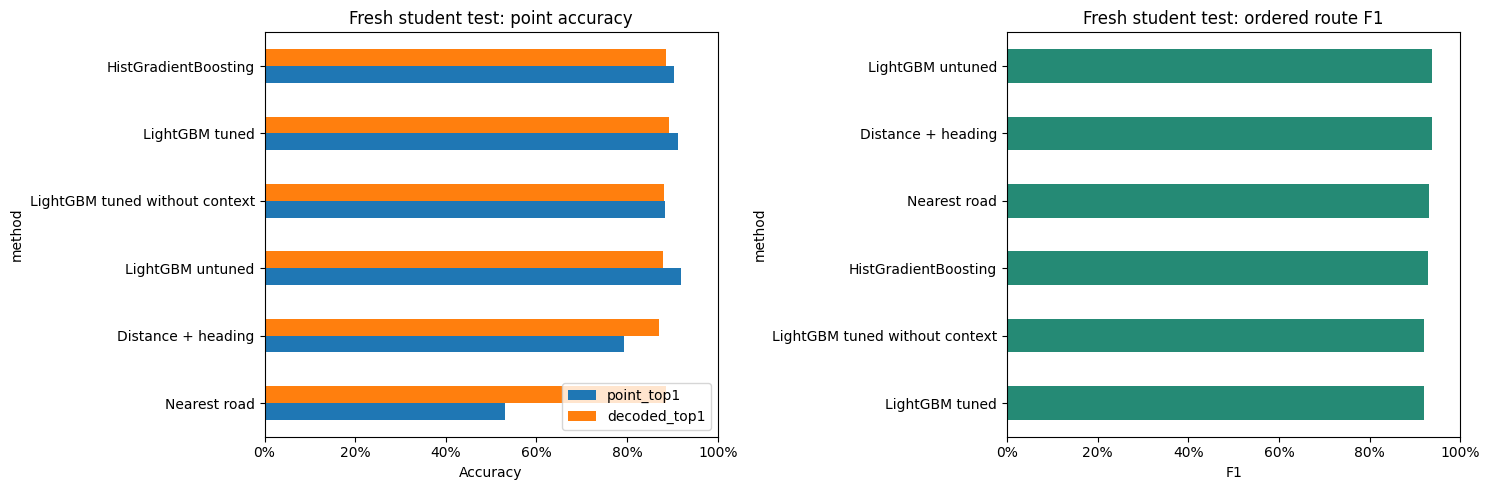

Completed at: 2026-11-18T12:44:23.609532+00:00
Project result directory: /content/pathsnap_review/pathsnap/work/colab-review


In [ ]:
fresh = pd.read_csv(result_dir / 'test_summary.csv').set_index('method')
selection = json.loads((result_dir / 'selection.json').read_text())
print('Selected deployment method:', selection['selected'])
print('Model fit trips:', selection['model_fit_trips'])
print('Fresh student-test comparison:')
display(fresh[['point_top1', 'decoded_top1', 'route_f1', 'trusted_covered_log_loss']].style.format({
    'point_top1': '{:.2%}', 'decoded_top1': '{:.2%}', 'route_f1': '{:.2%}',
    'trusted_covered_log_loss': '{:.3f}'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fresh[['point_top1', 'decoded_top1']].plot.barh(ax=axes[0])
axes[0].set(title='Fresh student test: point accuracy', xlabel='Accuracy', xlim=(0, 1))
axes[0].xaxis.set_major_formatter(PercentFormatter(xmax=1))
fresh['route_f1'].sort_values().plot.barh(ax=axes[1], color='#258a75')
axes[1].set(title='Fresh student test: ordered route F1', xlabel='F1', xlim=(0, 1))
axes[1].xaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.tight_layout()
plt.show()
print('Completed at:', datetime.now(timezone.utc).isoformat())
print('Project result directory:', result_dir)